In [1]:
import os
import sys
import jax

from jax import config
config.update("jax_enable_x64", True)
config.update("jax_debug_nans", True)

In [2]:
sys.path.append('../../')

In [3]:
from modules.gt_tree_gen import *
from modules.vis_utils import *
from modules.tree_func import *

In [4]:


metadata = {
    
     'n_all': 31,
     'n_ancestors': 15,
     'n_leaves': 16,
     'n_letters': 20,
     'n_mutations': 10,
     'seed': 43,
     'seq_length': 256,
            }

key = jax.random.PRNGKey(metadata['seed'])


n_leaves = metadata['n_leaves']
n_mutations = metadata['n_mutations']

_,__, adj = generate_general_groundtruth(metadata, perfect = True, seed = metadata['seed'], show_derivation = True)
# _,__, adj = generate_groundtruth(metadata, seed = 3)
_,__,adj


INFO : Perfect tree mode 


(Array([[0, 0, 0, ..., 0, 3, 0],
        [0, 0, 0, ..., 0, 3, 0],
        [0, 0, 0, ..., 0, 3, 2],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=bfloat16),
 Array([[0, 0, 0, ..., 0, 3, 0],
        [0, 0, 0, ..., 0, 3, 0],
        [0, 0, 0, ..., 0, 3, 2],
        ...,
        [0, 0, 0, ..., 0, 3, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=bfloat16),
 Array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
         0, 0, 0, 0

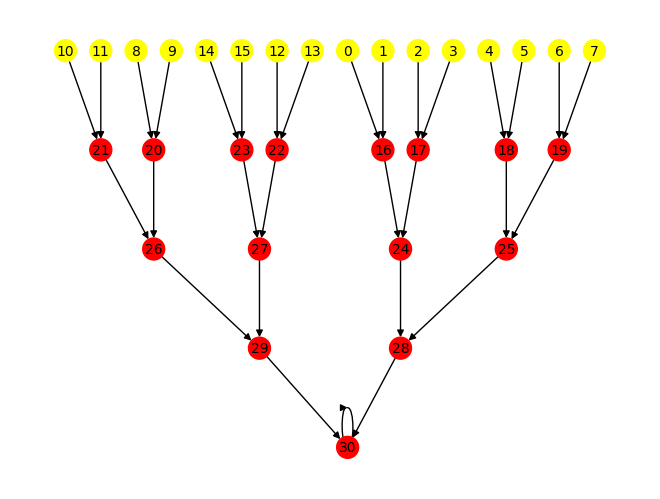

In [5]:
show_graph_with_labels(adj, n_leaves, return_img = True)

In [6]:
n_letters = metadata['n_letters']

In [7]:
sm = jnp.ones((metadata['n_letters'],metadata['n_letters'])) - jnp.identity(metadata['n_letters']).astype(jnp.float64)
gt_seqs = jax.nn.one_hot(__, n_letters).astype(jnp.float64)

adj = adj.at[-1,-1].set(1)

gt_cost = compute_cost(gt_seqs, adj, sm)

In [8]:
gt_cost

Array(300., dtype=float64)

In [9]:
print(f"Expected cost = {(n_leaves*2-2)*n_mutations}")

Expected cost = 300


In [10]:
__[0]

Array([0, 0, 0, 5, 0, 0, 0, 0, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 17, 0, 0, 0, 0, 0, 11, 11, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 14, 17,
       6, 0, 6, 1, 9, 0, 0, 0, 0, 0, 0, 6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 17, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 10, 0, 0, 0, 0, 1, 0, 0, 0, 0, 6, 0,
       4, 0, 0, 0, 0, 0, 0, 9, 0, 0, 0, 0, 0, 0, 0, 0, 12, 0, 0, 19, 5, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 14, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       3, 18, 19, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 15, 0, 0, 0,
       0, 0, 0, 8, 12, 0, 0, 0, 7, 0, 0, 0, 0, 0, 18, 0, 0, 0, 0, 0, 0, 0,
       4, 12, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 10, 0, 0, 0, 1, 0, 0,
       19, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 13, 0, 3, 0], dtype=bfloat16)

In [11]:
#https://wandb.ai/ramithx1/Batch-Run-Maximum-Parsimony-A100-META-optimized/runs/toujtm9e?nw=nwuserramithx1